In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__results__.html
/kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__resultx__.html
/kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__notebook__.ipynb
/kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__output__.json
/kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/custom.css
/kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__results___files/__results___60_1.png
/kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__results___files/__results___62_2.png
/kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__results___files/__results___78_1.png
/kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__results___files/__results___54_0.png
/kaggle/input/not

In [2]:
# ============================================================
# KNN Distance Metrics — Dimensionality Stratification Study
# FULL EXPERIMENT PIPELINE (v2 — auto-detects file paths)
# Paste into a Kaggle Notebook. No manual path editing needed —
# it searches /kaggle/input automatically for your uploaded files.
# ============================================================
 
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.datasets import load_iris, load_breast_cancer, fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.covariance import EmpiricalCovariance
 
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations
 
import warnings
warnings.filterwarnings("ignore")
 
RANDOM_STATE = 42
 
 

In [4]:
# ============================================================
# 0. AUTO-DISCOVER FILES UNDER /kaggle/input
# ============================================================
def find_file(keyword, prefer_substrings=None,
              exclude_substrings=(".names", ".json", "index", "datapackage")):
    """
    Walks /kaggle/input looking for filenames containing `keyword`
    (case-insensitive), excluding metadata files (.names, .json, Index, etc).
    If prefer_substrings is given, ranks matches so a preferred one
    (e.g. 'all-data', 'data.csv') is returned first.
    Returns the best match path, or None if nothing found.
    """
    keyword = keyword.lower()
    matches = []
    for dirname, _, filenames in os.walk("/kaggle/input"):
        for filename in filenames:
            fl = filename.lower()
            if keyword in fl and not any(ex in fl for ex in exclude_substrings):
                matches.append(os.path.join(dirname, filename))
 
    if not matches:
        return None
 
    if prefer_substrings:
        for pref in prefer_substrings:
            for m in matches:
                if pref.lower() in m.lower():
                    return m
 
    return matches[0]
 
 
def safe_read_csv(path, **kwargs):
    """
    Tries reading a CSV assuming no header (all-numeric first row).
    If that fails because the first row is actually text (a header),
    automatically retries with header=0.
    """
    try:
        df = pd.read_csv(path, header=None, **kwargs)
        # Sanity check: try converting the first row (excluding last col) to float.
        df.iloc[:, :-1].astype(float)
        return df, None  # None = no header was present
    except (ValueError, TypeError):
        df = pd.read_csv(path, header=0, **kwargs)
        return df, 0  # header row was present and used
 
 
def list_all_input_files():
    print("Files currently available under /kaggle/input:")
    found_any = False
    for dirname, _, filenames in os.walk("/kaggle/input"):
        for filename in filenames:
            print(" ", os.path.join(dirname, filename))
            found_any = True
    if not found_any:
        print("  (no files found — did you attach datasets via 'Add Input'?)")
 
 
def load_leukemia_dataset():
    """
    Loads a Leukemia gene expression dataset. Tries multiple known formats:
 
    Format A (CuMiDa — e.g. Leukemia_GSE9476.csv):
      Single CSV, first column = sample ID, second column = class label
      ('type'), remaining columns = gene expression values (samples as ROWS).
 
    Format B (classic Golub et al. train/independent + actual.csv):
      Genes as ROWS, patients as COLUMNS -> needs transposing.
 
    Returns (X, y) as numpy arrays, or None if nothing usable was found.
    """
    # ---- Format A: CuMiDa-style single file (e.g. "Leukemia_GSE9476.csv") ----
    cumida_path = find_file("leukemia", prefer_substrings=["GSE", ".csv"],
                             exclude_substrings=(".names", ".json", "index"))
    if cumida_path:
        try:
            df = pd.read_csv(cumida_path)
            cols_lower = [c.lower() for c in df.columns]
 
            # Identify the label column (commonly called "type") and drop the
            # sample-ID column (commonly the first column, e.g. "samples").
            label_col = None
            for candidate in ["type", "class", "label", "diagnosis"]:
                matches = [c for c in df.columns if c.lower() == candidate]
                if matches:
                    label_col = matches[0]
                    break
 
            if label_col is not None:
                id_cols = [c for c in df.columns
                           if df[c].dtype == object and c != label_col]
                feature_cols = [c for c in df.columns if c != label_col and c not in id_cols]
 
                X = df[feature_cols].values.astype(float)
                y = LabelEncoder().fit_transform(df[label_col].values)
 
                print(f"Parsed as CuMiDa format: {X.shape[0]} samples, {X.shape[1]} features, "
                      f"label column = '{label_col}'")
                return X, y
        except Exception as e:
            print(f"Found a Leukemia file but CuMiDa-style parsing failed: {e}")
            print("Trying classic Golub train/independent format instead...")
 
    # ---- Format B: classic Golub train + independent + actual.csv ----
    train_path = find_file("train", prefer_substrings=["all_aml", "leukemia"])
    indep_path = find_file("independent", prefer_substrings=["all_aml", "leukemia"])
    labels_path = find_file("actual", prefer_substrings=[".csv"])
 
    if train_path and labels_path:
        try:
            train_df = pd.read_csv(train_path)
            numeric_cols = [c for c in train_df.columns if str(train_df[c].dtype).startswith(("int", "float"))]
            expr_df = train_df[numeric_cols]  # rows = genes, columns = patient IDs
 
            if indep_path:
                indep_df = pd.read_csv(indep_path)
                indep_numeric_cols = [c for c in indep_df.columns
                                       if str(indep_df[c].dtype).startswith(("int", "float"))]
                indep_expr_df = indep_df[indep_numeric_cols]
                combined = pd.concat([expr_df, indep_expr_df], axis=1)
            else:
                combined = expr_df
 
            X = combined.T.values.astype(float)  # transpose: patients as rows, genes as columns
 
            labels_df = pd.read_csv(labels_path)
            label_col = [c for c in labels_df.columns if labels_df[c].dtype == object][0]
            y_raw = labels_df[label_col].values[:X.shape[0]]
            y = LabelEncoder().fit_transform(y_raw)
 
            if X.shape[0] == len(y):
                return X, y
            else:
                print(f"Leukemia dataset: sample count mismatch (X={X.shape[0]}, y={len(y)}). Skipping.")
                return None
        except Exception as e:
            print(f"Leukemia dataset found but failed to parse with Golub format either: {e}")
 
    print("Leukemia dataset not found or could not be parsed under /kaggle/input. Skipping.")
    return None
 
 

In [6]:
# ============================================================
# 1. LOAD ALL DATASETS
# ============================================================
def load_datasets():
    datasets = {}
 
    # ---------- LOW-DIMENSIONAL (built into sklearn, always works) ----------
    iris = load_iris()
    datasets["Iris"] = (iris.data, iris.target, "Low")
 
    bc = load_breast_cancer()
    datasets["BreastCancerWisconsin"] = (bc.data, bc.target, "Low")
 
    # ---------- MEDIUM-DIMENSIONAL ----------
    iono_path = find_file("ionosphere", prefer_substrings=["data.csv", "_data"])
    if iono_path:
        try:
            iono, header_used = safe_read_csv(iono_path)
            X = iono.iloc[:, :-1].values.astype(float)
            y = LabelEncoder().fit_transform(iono.iloc[:, -1].values)
            datasets["Ionosphere"] = (X, y, "Medium")
            print(f"Loaded Ionosphere from: {iono_path} (header_row={header_used is not None})")
        except Exception as e:
            print(f"Found Ionosphere file but failed to parse it: {e}")
    else:
        print("Ionosphere file not found under /kaggle/input. Skipping.")
 
    sonar_path = find_file("sonar", prefer_substrings=["all-data", "all_data", ".csv"])
    if sonar_path:
        try:
            sonar, header_used = safe_read_csv(sonar_path)
            X = sonar.iloc[:, :-1].values.astype(float)
            y = LabelEncoder().fit_transform(sonar.iloc[:, -1].values)
            datasets["Sonar"] = (X, y, "Medium")
            print(f"Loaded Sonar from: {sonar_path} (header_row={header_used is not None})")
        except Exception as e:
            print(f"Found Sonar file but failed to parse it: {e}")
    else:
        print("Sonar file not found under /kaggle/input. Skipping.")
 
    # ---------- HIGH-DIMENSIONAL ----------
    colon_path = find_file("colon", prefer_substrings=["labled", "label", ".csv"])
    if colon_path:
        try:
            colon, header_used = safe_read_csv(colon_path)
            X = colon.iloc[:, :-1].values.astype(float)
            y = LabelEncoder().fit_transform(colon.iloc[:, -1].values)
            datasets["ColonCancer"] = (X, y, "High")
            print(f"Loaded Colon Cancer from: {colon_path} (header_row={header_used is not None})")
        except Exception as e:
            print(f"Found Colon Cancer file but failed to parse it: {e}")
    else:
        print("Colon Cancer file not found under /kaggle/input. Skipping.")
 
    # 20 Newsgroups (backup — only runs if internet is available; skipped otherwise)
    try:
        categories = ["sci.med", "sci.space", "rec.sport.baseball", "talk.politics.guns"]
        news = fetch_20newsgroups(subset="train", categories=categories,
                                   remove=("headers", "footers", "quotes"),
                                   random_state=RANDOM_STATE)
        tfidf = TfidfVectorizer(max_features=1000, stop_words="english")
        X_news = tfidf.fit_transform(news.data)
        svd = TruncatedSVD(n_components=300, random_state=RANDOM_STATE)
        X_news_reduced = svd.fit_transform(X_news)
        datasets["20Newsgroups"] = (X_news_reduced, news.target, "High")
        print("Loaded 20 Newsgroups (via internet fetch).")
    except Exception as e:
        print(f"20 Newsgroups skipped (internet likely off): {e}")
 
    # Leukemia gene expression (Golub et al.) — classic HDLSS dataset.
    # Common Kaggle format: separate train/independent CSVs with genes as ROWS
    # and patients as COLUMNS (needs transposing), plus an 'actual.csv' labels file.
    leukemia_data = load_leukemia_dataset()
    if leukemia_data is not None:
        X_leuk, y_leuk = leukemia_data
        datasets["Leukemia"] = (X_leuk, y_leuk, "High")
        print(f"Loaded Leukemia gene expression dataset: {X_leuk.shape[0]} samples, "
              f"{X_leuk.shape[1]} features.")
 
    return datasets
 
 

In [10]:
# ============================================================
# 2. SUMMARIZE DATASETS (p/n ratio table for your Methodology section)
# ============================================================
def summarize_datasets(datasets):
    rows = []
    for name, (X, y, stratum) in datasets.items():
        n_samples, n_features = X.shape
        rows.append({
            "Dataset": name,
            "Features (p)": n_features,
            "Samples (n)": n_samples,
            "p/n ratio": round(n_features / n_samples, 4),
            "Classes": len(np.unique(y)),
            "Stratum": stratum,
        })
    summary_df = pd.DataFrame(rows)
    print("\n=== Dataset Summary ===")
    print(summary_df.to_string(index=False))
    return summary_df
 
 

In [12]:
# ============================================================
# 3. METRIC CONFIGURATIONS
# ============================================================
def get_metric_configs(X_train, skip_mahalanobis_if_extreme=True, extreme_ratio_threshold=5):
    """
    Returns metric configs. If the dataset is extremely high-dimensional
    relative to sample size (p/n ratio above threshold), Mahalanobis is
    skipped automatically — computing/inverting a huge covariance matrix
    (e.g. 22,000+ x 22,000+) is computationally intractable and not a
    meaningful comparison in that regime anyway. This is noted in the
    printed output so you can mention it in your Methodology section.
    """
    n_samples, n_features = X_train.shape
    p_over_n = n_features / n_samples
 
    configs = {
        "Euclidean":    ("minkowski", {"p": 2}),
        "Manhattan":    ("minkowski", {"p": 1}),
        "Minkowski_p3": ("minkowski", {"p": 3}),
        "Cosine":       ("cosine", {}),
    }
 
    if skip_mahalanobis_if_extreme and p_over_n > extreme_ratio_threshold:
        print(f"  [Note] p/n ratio = {p_over_n:.1f} (features={n_features}, samples={n_samples}) "
              f"— skipping Mahalanobis (covariance matrix too large / unstable to invert "
              f"reliably at this scale). This exclusion is worth mentioning in your paper's "
              f"Methodology/Limitations section.")
    else:
        cov = EmpiricalCovariance().fit(X_train)
        VI = np.linalg.pinv(cov.covariance_)
        configs["Mahalanobis"] = ("mahalanobis", {"VI": VI})
 
    return configs
 
 

In [13]:
# ============================================================
# 4. RUN EXPERIMENT ON ONE DATASET
# ============================================================
def run_experiment_on_dataset(name, X, y, stratum, scaled=True, k_range=range(1, 21)):
    results = []
 
    if scaled:
        X = StandardScaler().fit_transform(X)
 
    metric_configs = get_metric_configs(X)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
 
    for metric_name, (metric, params) in metric_configs.items():
        try:
            knn = KNeighborsClassifier(metric=metric, metric_params=params if params else None)
            param_grid = {"n_neighbors": list(k_range)}
 
            grid = GridSearchCV(knn, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
            grid.fit(X, y)
 
            best_k = grid.best_params_["n_neighbors"]
 
            knn_best = KNeighborsClassifier(n_neighbors=best_k, metric=metric,
                                             metric_params=params if params else None)
            fold_scores = cross_val_score(knn_best, X, y, cv=cv, scoring="f1_macro")
 
            results.append({
                "Dataset": name,
                "Stratum": stratum,
                "Scaled": scaled,
                "Metric": metric_name,
                "Best_K": best_k,
                "Mean_F1": fold_scores.mean(),
                "Std_F1": fold_scores.std(),
            })
        except Exception as e:
            print(f"  [{name}] Metric {metric_name} failed: {e}")
 
    return results
 
 


In [14]:
# ============================================================
# 5. RUN FULL EXPERIMENT ACROSS ALL DATASETS
# ============================================================
def run_full_experiment():
    print("Checking /kaggle/input contents first...\n")
    list_all_input_files()
 
    datasets = load_datasets()
    print(f"\nLoaded {len(datasets)} dataset(s) total.\n")
 
    if len(datasets) == 0:
        print("No datasets loaded — stopping.")
        return pd.DataFrame()
 
    summarize_datasets(datasets)
 
    all_results = []
    for name, (X, y, stratum) in datasets.items():
        print(f"\nRunning: {name} ({stratum}-dim, {X.shape[1]} features, {X.shape[0]} samples)")
        all_results.extend(run_experiment_on_dataset(name, X, y, stratum, scaled=True))
        all_results.extend(run_experiment_on_dataset(name, X, y, stratum, scaled=False))
 
    results_df = pd.DataFrame(all_results)
    results_df.to_csv("knn_full_results.csv", index=False)
    print("\nSaved full results to knn_full_results.csv")
    return results_df
 
 

In [15]:
# ============================================================
# 6. STATISTICAL TESTING: Friedman + Wilcoxon post-hoc (Bonferroni)
#    Uses only SciPy — no extra installs needed.
#    Results are now also EXPORTED to files, not just printed.
# ============================================================
def run_statistical_tests(results_df, scaled=True):
    """
    Runs Friedman test in two passes to handle missing Mahalanobis values
    (Mahalanobis is skipped for extreme-p/n datasets, so the results grid
    isn't complete for all 5 metrics across all datasets):
 
      Pass 1 ("core"): the 4 metrics present in every dataset
                       (Euclidean, Manhattan, Minkowski_p3, Cosine)
      Pass 2 ("with_mahalanobis"): all 5 metrics, but only across the
                       datasets where Mahalanobis was actually computed
    """
    subset = results_df[results_df["Scaled"] == scaled]
    pivot_full = subset.pivot_table(index="Dataset", columns="Metric", values="Mean_F1")
 
    friedman_rows = []
    posthoc_frames = []
 
    # ---- Pass 1: core metrics, all datasets ----
    core_metrics = [c for c in pivot_full.columns if c != "Mahalanobis"]
    pivot_core = pivot_full[core_metrics].dropna()
 
    print(f"\n--- Statistical Test: Core metrics, all datasets (Scaled={scaled}) ---")
    if pivot_core.shape[0] < 3:
        print(f"Need at least 3 datasets; have {pivot_core.shape[0]}. Skipping.")
        friedman_rows.append({"Scaled": scaled, "Test_Group": "core_metrics",
                               "N_datasets": pivot_core.shape[0],
                               "Statistic": None, "p_value": None, "Note": "Insufficient datasets"})
    else:
        stat, p_value = friedmanchisquare(*[pivot_core[c] for c in pivot_core.columns])
        print(f"Friedman statistic: {stat:.4f}, p-value: {p_value:.4f} "
              f"(n={pivot_core.shape[0]} datasets, metrics={list(pivot_core.columns)})")
        friedman_rows.append({"Scaled": scaled, "Test_Group": "core_metrics",
                               "N_datasets": pivot_core.shape[0],
                               "Statistic": stat, "p_value": p_value,
                               "Note": "Significant" if p_value < 0.05 else "Not significant"})
        if p_value < 0.05:
            posthoc_df = _wilcoxon_posthoc(pivot_core, scaled, "core_metrics")
            if posthoc_df is not None:
                posthoc_frames.append(posthoc_df)
 
    # ---- Pass 2: all 5 metrics, only datasets where Mahalanobis was computed ----
    if "Mahalanobis" in pivot_full.columns:
        pivot_maha = pivot_full.dropna()  # drops any dataset missing any metric, incl. Mahalanobis
 
        print(f"\n--- Statistical Test: All 5 metrics incl. Mahalanobis, "
              f"datasets where it was computed (Scaled={scaled}) ---")
        if pivot_maha.shape[0] < 3:
            print(f"Need at least 3 datasets; have {pivot_maha.shape[0]}. Skipping.")
            friedman_rows.append({"Scaled": scaled, "Test_Group": "with_mahalanobis",
                                   "N_datasets": pivot_maha.shape[0],
                                   "Statistic": None, "p_value": None, "Note": "Insufficient datasets"})
        else:
            stat, p_value = friedmanchisquare(*[pivot_maha[c] for c in pivot_maha.columns])
            print(f"Friedman statistic: {stat:.4f}, p-value: {p_value:.4f} "
                  f"(n={pivot_maha.shape[0]} datasets: {list(pivot_maha.index)})")
            friedman_rows.append({"Scaled": scaled, "Test_Group": "with_mahalanobis",
                                   "N_datasets": pivot_maha.shape[0],
                                   "Statistic": stat, "p_value": p_value,
                                   "Note": "Significant" if p_value < 0.05 else "Not significant"})
            if p_value < 0.05:
                posthoc_df = _wilcoxon_posthoc(pivot_maha, scaled, "with_mahalanobis")
                if posthoc_df is not None:
                    posthoc_frames.append(posthoc_df)
 
    friedman_df = pd.DataFrame(friedman_rows)
    posthoc_df_all = pd.concat(posthoc_frames, ignore_index=True) if posthoc_frames else None
    return friedman_df, posthoc_df_all
 
 
def _wilcoxon_posthoc(pivot, scaled, test_group):
    metrics = pivot.columns.tolist()
    pairs = list(combinations(metrics, 2))
    n_comparisons = len(pairs)
    alpha_corrected = 0.05 / n_comparisons
 
    posthoc_rows = []
    for m1, m2 in pairs:
        try:
            w_stat, w_p = wilcoxon(pivot[m1], pivot[m2])
        except ValueError:
            w_stat, w_p = np.nan, 1.0
        posthoc_rows.append({
            "Scaled": scaled,
            "Test_Group": test_group,
            "Metric_1": m1,
            "Metric_2": m2,
            "W_statistic": w_stat,
            "p_value": w_p,
            "Bonferroni_alpha": alpha_corrected,
            "Significant": w_p < alpha_corrected,
        })
    posthoc_df = pd.DataFrame(posthoc_rows)
    print(f"\nPairwise Wilcoxon post-hoc ({test_group}), Bonferroni alpha = {alpha_corrected:.5f}:")
    print(posthoc_df.round(5).to_string(index=False))
    return posthoc_df
 
 
def run_and_export_all_statistical_tests(results_df):
    """
    Runs Friedman + Wilcoxon post-hoc for both scaled and unscaled results,
    and exports everything to CSV files:
      - friedman_test_results.csv
      - wilcoxon_posthoc_results.csv (only created if at least one test was significant)
    """
    friedman_true, posthoc_true = run_statistical_tests(results_df, scaled=True)
    friedman_false, posthoc_false = run_statistical_tests(results_df, scaled=False)
 
    friedman_all = pd.concat([friedman_true, friedman_false], ignore_index=True)
    friedman_all.to_csv("friedman_test_results.csv", index=False)
    print("\nSaved Friedman test results to friedman_test_results.csv")
 
    posthoc_frames = [df for df in [posthoc_true, posthoc_false] if df is not None]
    if posthoc_frames:
        posthoc_all = pd.concat(posthoc_frames, ignore_index=True)
        posthoc_all.to_csv("wilcoxon_posthoc_results.csv", index=False)
        print("Saved Wilcoxon post-hoc results to wilcoxon_posthoc_results.csv")
    else:
        print("No post-hoc results to save (no significant Friedman test yet — "
              "likely because you have fewer than 3 datasets, or differences "
              "weren't significant).")
 
    return friedman_all, posthoc_frames
 
 

In [17]:
# ============================================================
# 7. VISUALIZATION — 4 paper-ready figures
# ============================================================
STRATUM_ORDER = ["Low", "Medium", "High"]
 
 
def plot_trend_line(results_df, scaled=True):
    """Figure 1: Mean F1 vs. dimensionality stratum, one line per metric."""
    subset = results_df[results_df["Scaled"] == scaled].copy()
    if subset.empty:
        return
 
    subset["Stratum"] = pd.Categorical(subset["Stratum"], categories=STRATUM_ORDER, ordered=True)
    agg = subset.groupby(["Stratum", "Metric"], observed=True)["Mean_F1"].mean().reset_index()
 
    plt.figure(figsize=(8, 5))
    sns.lineplot(data=agg, x="Stratum", y="Mean_F1", hue="Metric",
                 marker="o", linewidth=2)
    plt.title(f"Metric Performance Trend Across Dimensionality (Scaled={scaled})")
    plt.ylabel("Mean F1-score (averaged across datasets in stratum)")
    plt.xlabel("Dimensionality Stratum")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(f"fig1_trend_line_scaled_{scaled}.png", dpi=150)
    plt.show()
 
 
def plot_grouped_bar_by_dataset(results_df, scaled=True):
    """Figure 2: Grouped bar chart, one subplot per stratum, bars = dataset x metric."""
    subset = results_df[results_df["Scaled"] == scaled].copy()
    if subset.empty:
        return
 
    subset["Stratum"] = pd.Categorical(subset["Stratum"], categories=STRATUM_ORDER, ordered=True)
    strata_present = [s for s in STRATUM_ORDER if s in subset["Stratum"].unique()]
 
    fig, axes = plt.subplots(1, len(strata_present), figsize=(6 * len(strata_present), 5), sharey=True)
    if len(strata_present) == 1:
        axes = [axes]
 
    for ax, stratum in zip(axes, strata_present):
        stratum_data = subset[subset["Stratum"] == stratum]
        sns.barplot(data=stratum_data, x="Dataset", y="Mean_F1", hue="Metric", ax=ax)
        ax.set_title(f"{stratum}-Dimensional")
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=30)
        if ax != axes[0]:
            ax.set_ylabel("")
            ax.legend_.remove()
        else:
            ax.set_ylabel("Mean F1-score")
            ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
 
    plt.suptitle(f"Metric Performance by Dataset, Grouped by Stratum (Scaled={scaled})")
    plt.tight_layout()
    plt.savefig(f"fig2_grouped_bar_scaled_{scaled}.png", dpi=150)
    plt.show()
 
 
def plot_heatmap(results_df, scaled=True):
    """Figure 3: Heatmap of Dataset (rows) x Metric (columns) -> F1 score."""
    subset = results_df[results_df["Scaled"] == scaled].copy()
    if subset.empty:
        return
 
    pivot = subset.pivot_table(index="Dataset", columns="Metric", values="Mean_F1")
 
    # Order rows by stratum then dataset name for a readable layout
    stratum_map = subset.drop_duplicates("Dataset").set_index("Dataset")["Stratum"]
    pivot["_stratum"] = pivot.index.map(stratum_map)
    pivot["_stratum"] = pd.Categorical(pivot["_stratum"], categories=STRATUM_ORDER, ordered=True)
    pivot = pivot.sort_values("_stratum").drop(columns="_stratum")
 
    plt.figure(figsize=(8, max(3, 0.6 * len(pivot))))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0.4, vmax=1.0,
                linewidths=0.5, cbar_kws={"label": "Mean F1-score"})
    plt.title(f"F1-score by Dataset and Metric (Scaled={scaled})")
    plt.ylabel("Dataset")
    plt.xlabel("Distance Metric")
    plt.tight_layout()
    plt.savefig(f"fig3_heatmap_scaled_{scaled}.png", dpi=150)
    plt.show()
 
 
def plot_mahalanobis_collapse(results_df, scaled=True, highlight_metric="Mahalanobis",
                               reference_metrics=("Euclidean", "Cosine")):
    """
    Figure 4: Focused line plot highlighting how one metric (default: Mahalanobis)
    behaves across dimensionality strata, with a couple of reference metrics for context.
    """
    subset = results_df[results_df["Scaled"] == scaled].copy()
    if subset.empty:
        return
 
    subset["Stratum"] = pd.Categorical(subset["Stratum"], categories=STRATUM_ORDER, ordered=True)
    metrics_to_plot = [highlight_metric] + [m for m in reference_metrics if m != highlight_metric]
    subset = subset[subset["Metric"].isin(metrics_to_plot)]
 
    agg = subset.groupby(["Stratum", "Metric"], observed=True)["Mean_F1"].mean().reset_index()
 
    plt.figure(figsize=(7, 5))
    for metric in metrics_to_plot:
        metric_data = agg[agg["Metric"] == metric]
        linewidth = 3 if metric == highlight_metric else 1.5
        linestyle = "-" if metric == highlight_metric else "--"
        plt.plot(metric_data["Stratum"], metric_data["Mean_F1"], marker="o",
                  linewidth=linewidth, linestyle=linestyle, label=metric)
 
    plt.title(f"{highlight_metric} Performance vs. Reference Metrics (Scaled={scaled})")
    plt.ylabel("Mean F1-score")
    plt.xlabel("Dimensionality Stratum")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"fig4_{highlight_metric.lower()}_collapse_scaled_{scaled}.png", dpi=150)
    plt.show()
 
 
def generate_all_figures(results_df):
    for scaled in [True, False]:
        plot_trend_line(results_df, scaled=scaled)
        plot_grouped_bar_by_dataset(results_df, scaled=scaled)
        plot_heatmap(results_df, scaled=scaled)
        plot_mahalanobis_collapse(results_df, scaled=scaled)
 
 


Checking /kaggle/input contents first...

Files currently available under /kaggle/input:
  /kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__results__.html
  /kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__resultx__.html
  /kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__notebook__.ipynb
  /kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__output__.json
  /kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/custom.css
  /kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__results___files/__results___60_1.png
  /kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__results___files/__results___62_2.png
  /kaggle/input/notebooks/selinyang/gene-expression-data-for-acute-leukemia-patients/__results___files/__results___78_1.png
  /kaggle/input/notebooks/selinyan

/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The 


Running: BreastCancerWisconsin (Low-dim, 30 features, 569 samples)


/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The 


Running: Ionosphere (Medium-dim, 34 features, 351 samples)


/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The 

... (7 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The 

  [Note] p/n ratio = 348.2 (features=22284, samples=64) — skipping Mahalanobis (covariance matrix too large / unstable to invert reliably at this scale). This exclusion is worth mentioning in your paper's Methodology/Limitations section.


/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The corresponding parameter from __init__ is ignored.
  return self._fit(X, y)
/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: SyntaxWarning: Parameter p is found in metric_params. The 


Saved full results to knn_full_results.csv

=== Results Summary (sorted) ===
              Dataset Stratum  Scaled       Metric  Best_K  Mean_F1   Std_F1
          ColonCancer    High   False       Cosine       7 0.875061 0.041959
          ColonCancer    High   False    Euclidean       3 0.815224 0.107369
          ColonCancer    High   False    Manhattan       1 0.799395 0.069310
          ColonCancer    High   False Minkowski_p3       1 0.792274 0.047499
          ColonCancer    High    True    Manhattan       3 0.774118 0.095733
          ColonCancer    High    True    Euclidean       1 0.750170 0.058910
          ColonCancer    High    True Minkowski_p3       3 0.690522 0.165501
          ColonCancer    High    True       Cosine       2 0.668515 0.091406
             Leukemia    High   False Minkowski_p3       1 1.000000 0.000000
             Leukemia    High   False    Euclidean       1 0.975919 0.029521
             Leukemia    High   False       Cosine       1 0.975919 0.02952

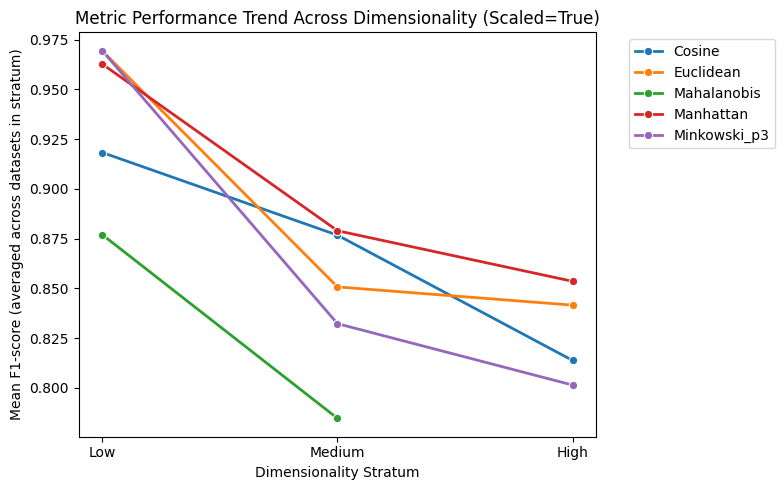

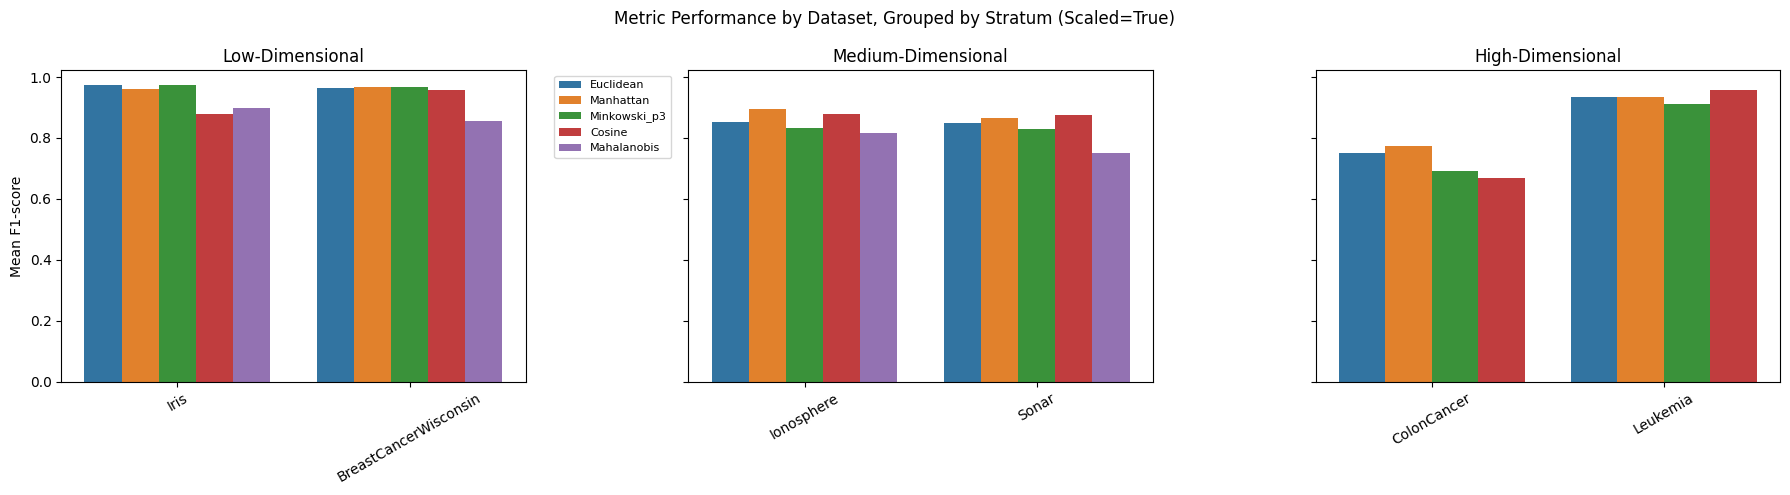

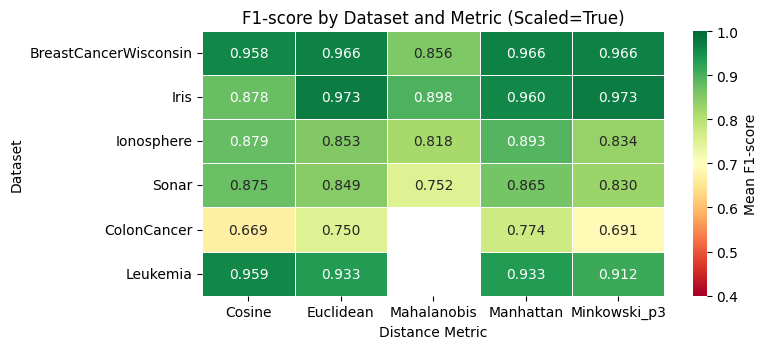

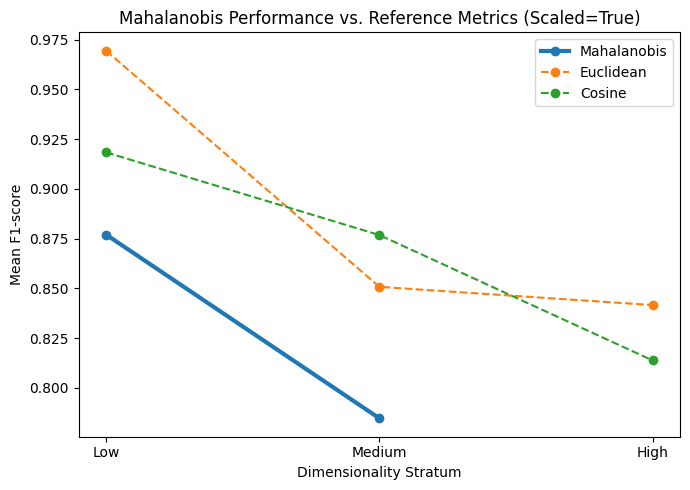

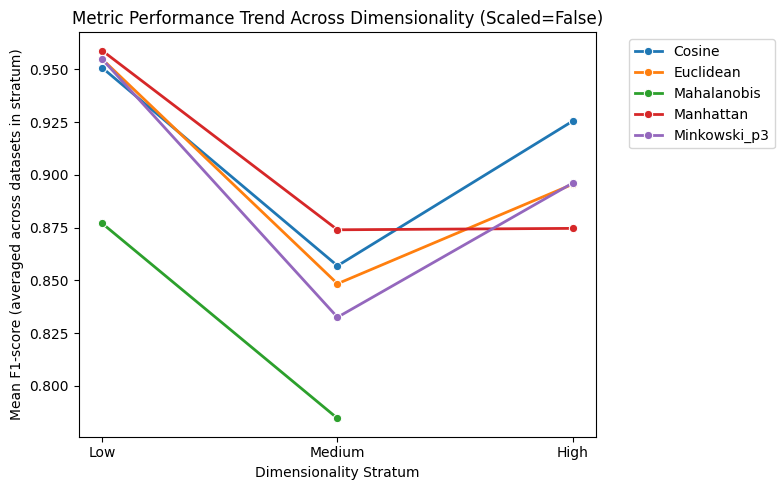

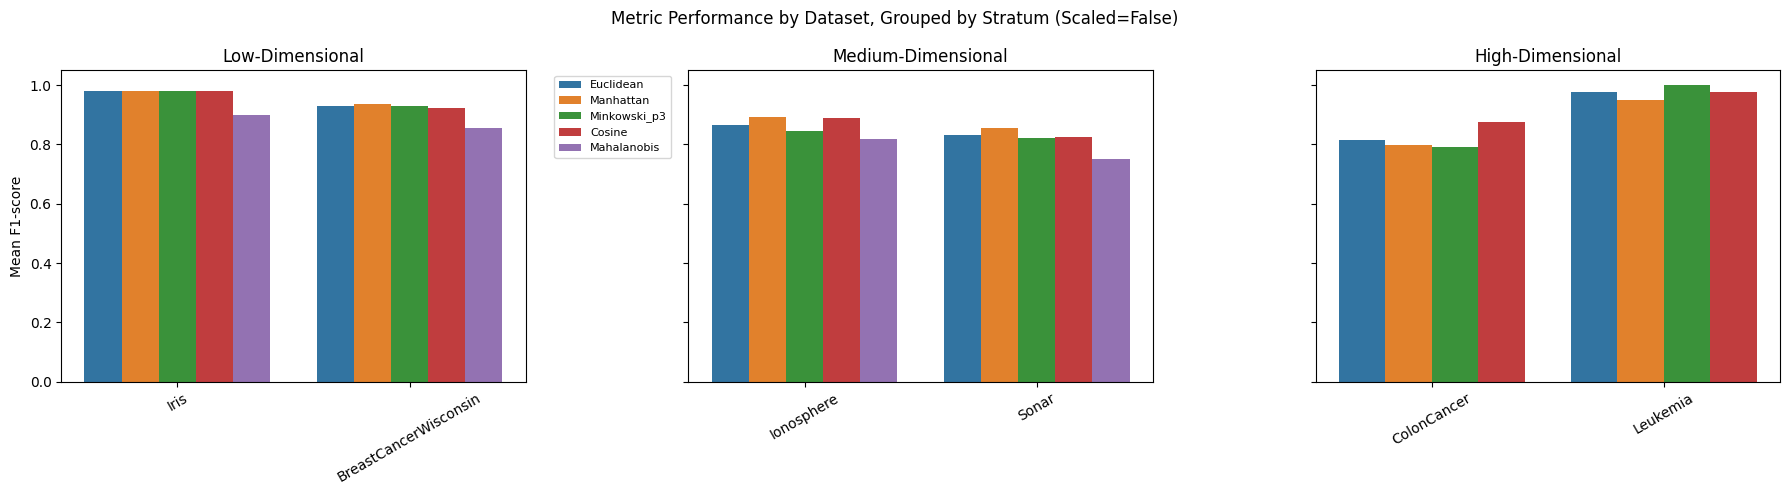

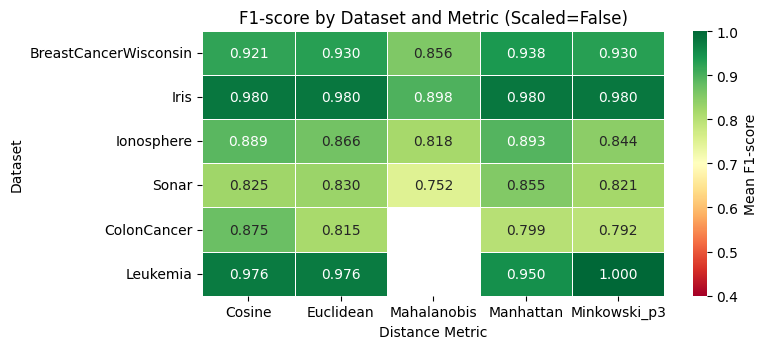

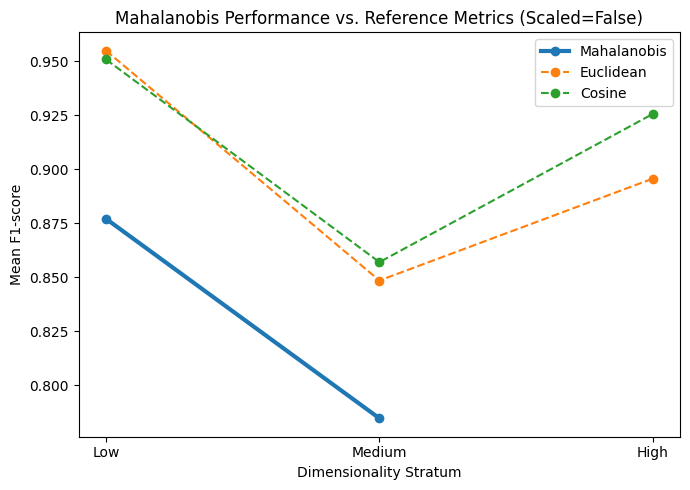


Done. Check these output files for your paper:
  - knn_full_results.csv           (raw results)
  - friedman_test_results.csv      (Friedman test statistics)
  - wilcoxon_posthoc_results.csv   (pairwise significance, if applicable)
  - fig1_trend_line_scaled_*.png
  - fig2_grouped_bar_scaled_*.png
  - fig3_heatmap_scaled_*.png
  - fig4_mahalanobis_collapse_scaled_*.png


In [18]:
# ============================================================
# 8. RUN EVERYTHING
# ============================================================
if __name__ == "__main__":
    results_df = run_full_experiment()
 
    if not results_df.empty:
        print("\n=== Results Summary (sorted) ===")
        print(results_df.sort_values(["Stratum", "Dataset", "Scaled", "Mean_F1"],
                                      ascending=[True, True, True, False]).to_string(index=False))
 
        run_and_export_all_statistical_tests(results_df)
        generate_all_figures(results_df)
 
        print("\nDone. Check these output files for your paper:")
        print("  - knn_full_results.csv           (raw results)")
        print("  - friedman_test_results.csv      (Friedman test statistics)")
        print("  - wilcoxon_posthoc_results.csv   (pairwise significance, if applicable)")
        print("  - fig1_trend_line_scaled_*.png")
        print("  - fig2_grouped_bar_scaled_*.png")
        print("  - fig3_heatmap_scaled_*.png")
        print("  - fig4_mahalanobis_collapse_scaled_*.png")
    else:
        print("\nNo results generated. Fix dataset loading issues above and re-run.")
 